### KDD · Fase 2: Preprocesamiento

Revisión de la calidad de los datos y limpieza. Las reglas se definen con el grupo de entrenamiento y se aplican igual al de prueba.

- **Entradas:** `kdd/data/interim/train.csv`, `kdd/data/interim/test.csv`
- **Salidas:**
  - `kdd/data/interim/train_clean.csv`, `kdd/data/interim/test_clean.csv`: datos limpios
  - `kdd/figures/preprocessing_boxplots.png`: diagramas de caja por especie

#### Librerías

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

#### Rutas

Relativas a la carpeta del notebook.

In [2]:
INTERIM_DIR = Path("../data/interim")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#### Estilo de las figuras

In [3]:
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COLORS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "font.size": 10,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

#### Carga de datos

In [4]:
train = pd.read_csv(INTERIM_DIR / "train.csv")
test = pd.read_csv(INTERIM_DIR / "test.csv")

TARGET = "species"
NUMERIC = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["island", "sex"]

print(f"Entrenamiento: {train.shape} | Prueba: {test.shape}")

Entrenamiento: (275, 8) | Prueba: (69, 8)


#### Valores faltantes

In [5]:
pd.DataFrame({
    "train": train.isna().sum(),
    "test": test.isna().sum(),
})

,train,test
row_id,0,0
species,0,0
island,0,0
culmen_length_mm,2,0
culmen_depth_mm,2,0
flipper_length_mm,2,0
body_mass_g,2,0
sex,8,2


#### Registros con valores faltantes en entrenamiento

In [6]:
train[train.isna().any(axis=1)]

,row_id,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
18,3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
72,9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
113,286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
170,10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
180,324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
210,339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
237,11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
244,47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN


#### Valores de las variables categóricas

In [7]:
for col in CATEGORICAL:
    counts = pd.DataFrame({
        "train": train[col].value_counts(dropna=False),
        "test": test[col].value_counts(dropna=False),
    }).fillna(0).astype(int)
    print(f"--- {col} ---")
    print(counts.to_string(), "\n")

--- island ---
           train  test
island                
Biscoe       133    35
Dream        101    23
Torgersen     41    11 

--- sex ---
        train  test
sex                
.           0     1
FEMALE    134    31
MALE      133    35
NaN         8     2 



#### Filas repetidas

In [8]:
dup = train.drop(columns="row_id").duplicated().sum()
print(f"Filas repetidas en entrenamiento: {dup}")

Filas repetidas en entrenamiento: 0


#### Valores atípicos por especie

Valores fuera de 1.5 veces el rango intercuartílico, calculado dentro de cada especie.

In [9]:
def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


train.groupby(TARGET)[NUMERIC].agg(count_iqr_outliers)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,0,1,1,0
Chinstrap,1,0,1,2
Gentoo,2,0,0,0


#### Diagramas de caja por especie

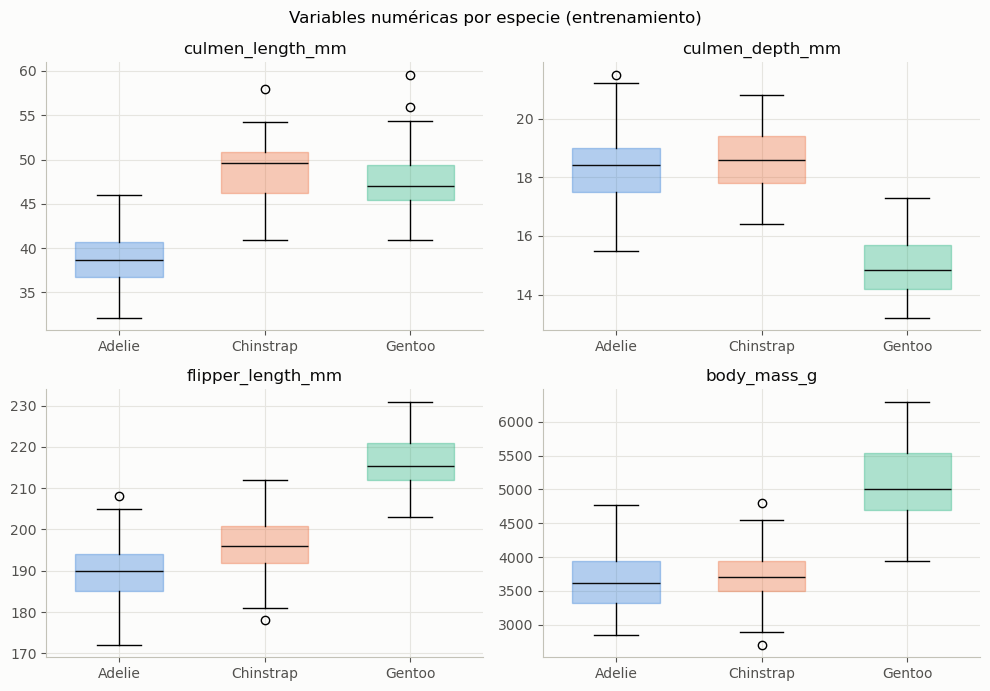

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, col in zip(axes.flat, NUMERIC):
    data = [train.loc[train[TARGET] == sp, col].dropna() for sp in SPECIES]
    box = ax.boxplot(data, patch_artist=True, widths=0.6)
    ax.set_xticks(range(1, len(SPECIES) + 1), SPECIES)
    for patch, sp in zip(box["boxes"], SPECIES):
        patch.set_facecolor(COLORS[sp])
        patch.set_alpha(0.35)
        patch.set_edgecolor(COLORS[sp])
    for median in box["medians"]:
        median.set_color("#0b0b0b")
    ax.set_title(col)

fig.suptitle("Variables numéricas por especie (entrenamiento)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "preprocessing_boxplots.png")
plt.show()

#### Eliminación de registros sin medidas

In [11]:
def drop_without_measures(df):
    return df[df[NUMERIC].notna().any(axis=1)].copy()


removed = train[train[NUMERIC].isna().all(axis=1)]["row_id"].tolist()
removed_test = test[test[NUMERIC].isna().all(axis=1)]["row_id"].tolist()

train = drop_without_measures(train)
test = drop_without_measures(test)

print(f"Eliminados en entrenamiento: {removed}")
print(f"Eliminados en prueba: {removed_test}")

Eliminados en entrenamiento: [3, 339]
Eliminados en prueba: []


#### Tratamiento de `sex`

Todo valor distinto de `MALE` o `FEMALE` pasa a `UNKNOWN`.

In [12]:
VALID_SEX = ["MALE", "FEMALE"]


def clean_sex(df):
    df["sex"] = df["sex"].where(df["sex"].isin(VALID_SEX), "UNKNOWN")
    return df


train = clean_sex(train)
test = clean_sex(test)

pd.DataFrame({
    "train": train["sex"].value_counts(),
    "test": test["sex"].value_counts(),
}).fillna(0).astype(int)

,train,test
sex,,
FEMALE,134,31
MALE,133,35
UNKNOWN,6,3


#### Verificación de datos limpios

In [13]:
pd.DataFrame({
    "faltantes_train": train.isna().sum(),
    "faltantes_test": test.isna().sum(),
})

,faltantes_train,faltantes_test
row_id,0,0
species,0,0
island,0,0
culmen_length_mm,0,0
culmen_depth_mm,0,0
flipper_length_mm,0,0
body_mass_g,0,0
sex,0,0


#### Guardado de resultados

In [14]:
train.to_csv(INTERIM_DIR / "train_clean.csv", index=False)
test.to_csv(INTERIM_DIR / "test_clean.csv", index=False)

print(f"Entrenamiento: {train.shape} | Prueba: {test.shape}")
for path in [INTERIM_DIR / "train_clean.csv", INTERIM_DIR / "test_clean.csv", FIGURES_DIR / "preprocessing_boxplots.png"]:
    print(f"Guardado: {path}")

Entrenamiento: (273, 8) | Prueba: (69, 8)
Guardado: ..\data\interim\train_clean.csv
Guardado: ..\data\interim\test_clean.csv
Guardado: ..\figures\preprocessing_boxplots.png
